# Advanced SNR

**Part:** J — Advanced topics · **Reading time:** ~60 min · **Pass 1 overview:** [Contrast and Image Quality](../pass1_big_picture/P1.4_Contrast_and_Image_Quality.ipynb) · **Refreshers you may want:** [Continuous FT and DFT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb), [Induction and RF](../refreshers/RP2_Induction_and_RF.ipynb) · **Prerequisites:** [Signal to Noise Ratio](G2_Signal_to_Noise_Ratio.ipynb), [Accelerated Imaging Methods](H3_Accelerated_Imaging_Methods.ipynb)

The basic SNR chapter gives the famous proportionality $SNR\propto\text{voxel volume}\times\sqrt{T_{meas}}$. This chapter tests its assumptions and goes beyond them: what happens when the signal decays during a long readout, how to choose TR and flip angle for the best **SNR per unit time**, and — most important in modern scanners with 8–64 receive channels — how noise in different coils is **correlated** and how to combine the coil signals optimally (the **Roemer** combination) versus the common **sum-of-squares**. We finish with the **g-factor** of parallel imaging, derived with the same machinery.

## Learning goals

1. Simulate SNR efficiency and explain challenges to the fundamental assumptions of the SNR equation (e.g. $T_2^*$ decay during the readout).
2. Derive the optimal readout duration for one- and two-sided $T_2^*$ decay.
3. Derive why spoiled gradient-echo SNR efficiency at the Ernst angle is nearly independent of TR for $TR\ll T_1$.
4. Define the noise covariance matrix of a coil array and estimate it from a noise scan.
5. Derive the SNR-optimal (Roemer) coil combination and compare it with sum-of-squares, with and without noise pre-whitening.
6. Derive and compute the SENSE g-factor.

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $SNR$ | signal-to-noise ratio (signal amplitude / noise standard deviation) | – | 10–100 in clinical images |
| $T_{read}$ | readout (ADC sampling) duration per echo | s | 2–10 ms (2DFT), up to ~50 ms (spiral/EPI) |
| $T_{meas}$ | total ADC sampling time for an image | s | |
| $\tau$ | dummy integration variable (time relative to readout start or echo) | s | |
| $T_1$, $T_2^*$ | relaxation time constants | s | |
| $x=T_{read}/T_2^*$ | readout duration in units of $T_2^*$ | – | optimum ≈ 1.26 (one-sided) |
| $\theta$, $\theta_E$ | flip angle; Ernst angle $\arccos E_1$ | rad | |
| $E_1=e^{-TR/T_1}$ | longitudinal recovery factor per TR | – | |
| $TR$, $TE$ | repetition time, echo time | s | |
| $f_{seq}$ | sequence-dependent signal factor (e.g. steady-state signal of spoiled GRE) | – (fraction of $M_0$) | |
| $\eta$ | SNR efficiency $=SNR/\sqrt{T_{scan}}$ (here signal$/\sqrt{TR}$) | s$^{-1/2}$ | |
| $M_0$ | equilibrium magnetization (normalized to 1) | – | |
| $N_c$ | number of receive coil elements (channels) | – | 8–64 |
| $n$, $n'$ | coil indices | – | |
| $C_n(\vec r)$, $\mathbf c$ | complex receive sensitivity of coil $n$; vector of all $N_c$ sensitivities at one pixel | – | |
| $m$ | true (complex) image value at a pixel | a.u. | |
| $\mathbf s=\mathbf c\,m+\boldsymbol\eta$ | vector of the $N_c$ coil image values at one pixel | a.u. | |
| $\boldsymbol\eta$ | vector of noise values in the $N_c$ coils (not the efficiency $\eta$ — context) | a.u. | zero mean, complex Gaussian |
| $\boldsymbol\Psi$, $\Psi_{nn'}$ | noise covariance matrix, $\Psi_{nn'}=E[\eta_n\eta_{n'}^*]$ | a.u.² | Hermitian, positive definite |
| $\rho_{nn'}$ | noise correlation coefficient $\Psi_{nn'}/\sqrt{\Psi_{nn}\Psi_{n'n'}}$ | – | neighbours 0.05–0.4 |
| $\mathbf w$ | coil combination weights, $\hat m=\mathbf w^H\mathbf s$ | – | |
| $\mathbf L$ | Cholesky factor, $\boldsymbol\Psi=\mathbf L\mathbf L^H$ | | used for pre-whitening |
| $^H$, $^*$ | conjugate transpose; complex conjugate | | |
| $E[\cdot]$ | expectation (average over noise realisations) | | |
| $\sigma$, $\sigma_n$ | noise standard deviation (per real/imaginary part) | a.u. | |
| $R$, $g$ | acceleration factor; g-factor | – | $SNR_{acc}=SNR/(g\sqrt R)$ |
| $\mathbf S$ | $N_c\times R$ sensitivity (encoding) matrix of the $R$ aliased pixels | – | |
| $k_B$, $T$, $R_{coil}$, $BW$ | Boltzmann constant, temperature, resistance, bandwidth (in the noise formula) | J/K, K, Ω, Hz | Johnson noise $\sigma^2=4k_BTR_{coil}BW$ |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. Recap: where noise comes from and why $SNR\propto\sqrt{T_{meas}}$

The noise in MRI is **thermal (Johnson) noise**: random motion of electrons in the conductive patient tissue and in the coil and preamplifier produces a random voltage with variance $\sigma^2=4k_BTR_{coil}BW$ — proportional to the temperature $T$ [K], the effective resistance $R_{coil}$ [Ω] seen by the coil (patient losses usually dominate at ≥ 1.5 T) and the receiver bandwidth $BW$ [Hz] ([RF System and Receive Chain](B5_RF_System_and_Receive_Chain.ipynb)). Each ADC sample carries an independent noise value of variance $\sigma^2\propto BW=1/\Delta t$.

Averaging $N$ independent samples with equal signal: the signal stays the same, the noise standard deviation drops by $\sqrt N$. An image pixel is (via the DFT) a weighted sum of all $N_{tot}$ k-space samples, so $SNR\propto\sqrt{N_{tot}\,\Delta t}=\sqrt{T_{meas}}$. **This assumes every sample carries the same signal** — the first assumption we challenge.

## 2. SNR and $T_2^*$ decay during the readout

The SNR equation alone implies that the readout time should be as long as possible, as this leads to more total measurement time, but practically this is limited by the $T_2^*$ decay, since at some point there is no longer any signal to measure. To incorporate the effect of this decay, we account for the signal modulation during the readout by integrating the signal over the readout, which offsets the gains from extending it:

$$SNR \propto \frac{ \int_0^{T_{read}} \exp(-\tau / T_2^*)\, d\tau } { \sqrt{T_{read}} }$$

In words: the numerator is the total signal collected during the readout (for a gradient echo the signal decays monotonically from the start of the readout, "one-sided"), and the denominator captures how the total noise standard deviation grows with the square root of the measurement time.
Where: $T_{read}$ [s] = readout duration; $\tau$ [s] = time since the start of the readout; $T_2^*$ [s].

For a two-sided decay, as around a spin echo (where the signal is refocused at the echo centre and decays with $T_2^*$ on both sides; strictly with $T_2'$ plus $T_2$), the readout is centred on the echo:

$$SNR \propto \frac{\int_{-T_{read}/2}^{T_{read}/2} \exp(-|\tau| / T_2^*)\, d\tau }{\sqrt{T_{read}}}$$

*(Correction: the original wrote $|\exp(-\tau/T_2^*)|$, which grows for $\tau<0$; the decay is $\exp(-|\tau|/T_2^*)$.)* Here $\tau$ is the time relative to the echo centre.

<details><summary><b>📐 Derivation (optional): closed forms and optimum</b></summary>

One-sided: $\int_0^{T_{read}}e^{-\tau/T_2^*}d\tau=T_2^*(1-e^{-T_{read}/T_2^*})$. With $x=T_{read}/T_2^*$: $SNR\propto\sqrt{T_2^*}\,\frac{1-e^{-x}}{\sqrt x}$. Setting the derivative to zero: $\frac{e^{-x}}{\sqrt x}-\frac{1-e^{-x}}{2x^{3/2}}=0\Rightarrow 2x\,e^{-x}=1-e^{-x}\Rightarrow e^{x}=1+2x$, whose positive root is $x\approx1.256$.

Two-sided: $\int_{-T/2}^{T/2}e^{-|\tau|/T_2^*}d\tau=2T_2^*(1-e^{-T/(2T_2^*)})$, so $SNR\propto\sqrt{T_2^*}\,\frac{2(1-e^{-x/2})}{\sqrt x}$. Substituting $u=x/2$ gives the same equation in $u$, hence $x=2\times1.256\approx2.51$.

</details>

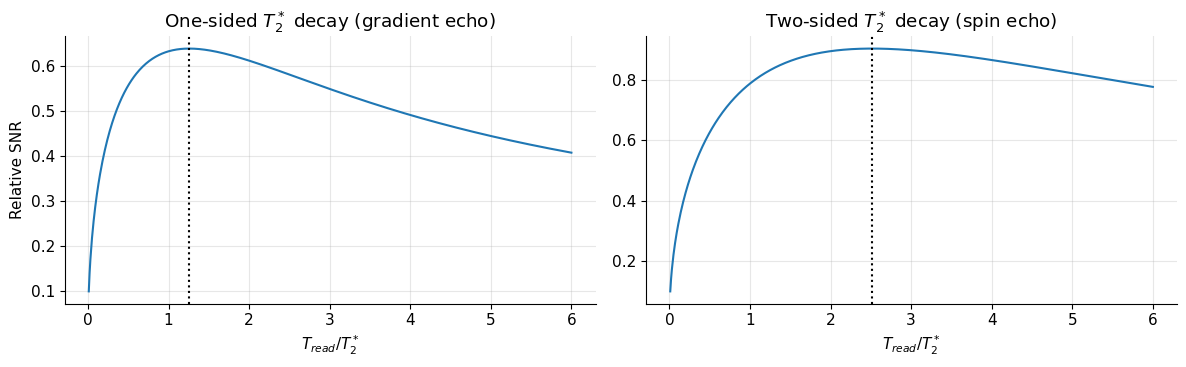

Maximum for one-sided decay: T_read/T2* = 1.26 (exact 1.256)
Maximum for two-sided decay: T_read/T2* = 2.51 (exact 2.513)
SNR at T_read = 0.3 T2* relative to the optimum (one-sided): 0.74


In [2]:
from scipy.optimize import brentq
Tread = np.linspace(0.01, 6, 600)          # T_read in units of T2*
T2s = 1
SNR_T2s_onesided = T2s * (1 - np.exp(-Tread / T2s)) / np.sqrt(Tread)
SNR_T2s_twosided = T2s * 2 * (1 - np.exp(-Tread / 2 / T2s)) / np.sqrt(Tread)
x_opt = brentq(lambda x: np.exp(x) - 1 - 2 * x, 0.5, 3)      # exact root of e^x = 1 + 2x

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(Tread, SNR_T2s_onesided); ax[0].axvline(x_opt, ls=":", color="k")
ax[0].set_xlabel(r"$T_{read} / T_2^*$"); ax[0].set_ylabel("Relative SNR")
ax[0].set_title(r"One-sided $T_2^*$ decay (gradient echo)")
ax[1].plot(Tread, SNR_T2s_twosided); ax[1].axvline(2 * x_opt, ls=":", color="k")
ax[1].set_xlabel(r"$T_{read} / T_2^*$"); ax[1].set_title(r"Two-sided $T_2^*$ decay (spin echo)")
plt.tight_layout(); plt.show()
print(f"Maximum for one-sided decay: T_read/T2* = {Tread[np.argmax(SNR_T2s_onesided)]:.2f} (exact {x_opt:.3f})")
print(f"Maximum for two-sided decay: T_read/T2* = {Tread[np.argmax(SNR_T2s_twosided)]:.2f} (exact {2*x_opt:.3f})")
print(f"SNR at T_read = 0.3 T2* relative to the optimum (one-sided): "
      f"{(1-np.exp(-0.3))/np.sqrt(0.3) / ((1-np.exp(-x_opt))/np.sqrt(x_opt)):.2f}")

From this result, the optimal choice of $T_{read}$ from an SNR point of view is approximately $T_{read}/T_2^* = 1.3$ (one-sided) and $T_{read}/T_2^* = 2.5$ (two-sided). The maximum is broad: a readout of only $0.3\,T_2^*$ still reaches ~70 % of the optimal SNR.

However, this relationship does not take into account the **resolution loss** that occurs because of the decaying $T_2^*$ weighting in k-space ([Point Spread Function Analysis](I1_Point_Spread_Function_Analysis.ipynb), Section 4): at $T_{read}=1.3\,T_2^*$ the PSF is already ~15 % wider than the ideal sinc, and off-resonance shifts grow proportionally to $T_{read}$. In practice readouts are chosen shorter than the SNR optimum (except in SNR-starved applications such as spiral imaging of hyperpolarized or X-nuclei).

## 3. SNR efficiency versus TR

**SNR efficiency** is the SNR per square root of scan time, $\eta=SNR/\sqrt{T_{scan}}$: two protocols with equal efficiency reach equal SNR in equal total time (by averaging). For a sequence repeated every $TR$ with a fixed readout per TR, $\eta\propto f_{seq}/\sqrt{TR}$, where $f_{seq}$ is the steady-state signal per excitation. It is especially interesting for spoiled gradient-echo sequences, where we can choose the optimal flip angle (the **Ernst angle**) for a $T_1$ of interest. For these sequences (see [Signal to Noise Ratio](G2_Signal_to_Noise_Ratio.ipynb) and [Basic Contrast Mechanisms](D1_Basic_Contrast_Mechanisms.ipynb))

$$f_{seq,GRE}=M_0\frac{\sin\theta\,(1-E_1)}{1-\cos\theta\,E_1}e^{-TE/T_2^*},\qquad \theta_{optimal} = \cos^{-1} \exp(-TR/T_1)$$

In words: the spoiled-GRE steady-state signal, and the flip angle that maximizes it.
Where: $\theta$ = flip angle [rad]; $E_1=e^{-TR/T_1}$; $TE$, $T_2^*$ as usual (set $TE=0$ below to isolate the $T_1$ effect). *(The original said "$f_{seq,GRE}$ is defined above", referring to another chapter; it is written out here.)*

<details><summary><b>📐 Derivation (optional): why the efficiency plateaus at short TR</b></summary>

At the Ernst angle $\cos\theta=E_1$, $\sin\theta=\sqrt{1-E_1^2}$, so

$$f_{seq}=M_0\frac{\sqrt{1-E_1^2}\,(1-E_1)}{1-E_1^2}=M_0\sqrt{\frac{1-E_1}{1+E_1}}.$$

For $TR\ll T_1$, $E_1\approx1-TR/T_1$, so $f_{seq}\approx M_0\sqrt{TR/(2T_1)}$ and

$$\eta=\frac{f_{seq}}{\sqrt{TR}}\approx\frac{M_0}{\sqrt{2T_1}},$$

independent of TR. For long TR, $E_1\to0$, $f_{seq}\to M_0$ and $\eta\to M_0/\sqrt{TR}$ falls.

</details>

Under this condition we see the following result: once the optimal flip angle approaches 90°, the SNR efficiency drops, but for shorter TRs the SNR efficiency is nearly constant for different TRs.

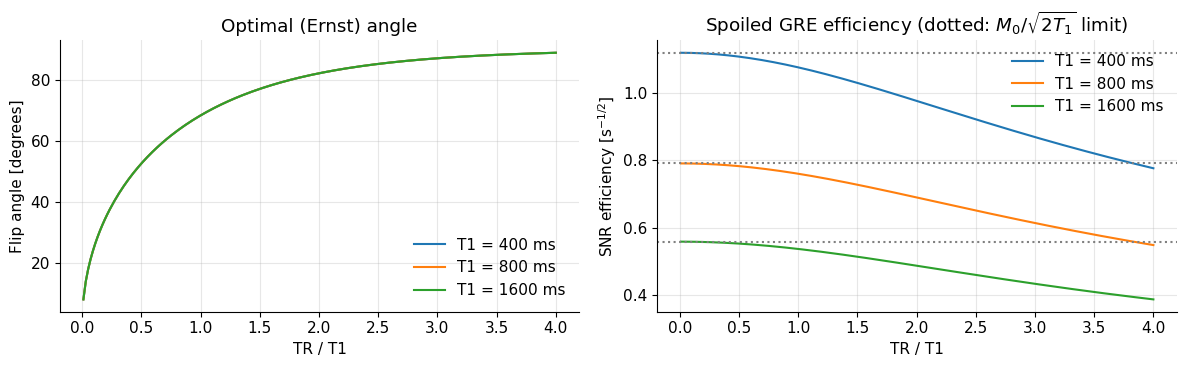

In [3]:
# SNR efficiency for spoiled gradient-echo pulse sequences at the Ernst angle (TE = 0)
TRdT1 = np.linspace(0.01, 4, 200)
T1 = np.array([0.4, 0.8, 1.6])                     # [s]
M0 = 1
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for T1_value in T1:
    TR = TRdT1 * T1_value
    theta_opt = mt.ernst_angle(TR, T1_value)
    signal = mt.spoiled_gre_signal(theta_opt, 0.0, TR, T1_value, np.inf, M0)
    eta = signal / np.sqrt(TR)                      # SNR efficiency [s^-1/2]
    ax[0].plot(TRdT1, np.degrees(theta_opt), label=f"T1 = {T1_value*1e3:.0f} ms")
    ax[1].plot(TRdT1, eta, label=f"T1 = {T1_value*1e3:.0f} ms")
    ax[1].axhline(M0 / np.sqrt(2 * T1_value), ls=":", color="0.5")
ax[0].set_xlabel("TR / T1"); ax[0].set_ylabel("Flip angle [degrees]"); ax[0].set_title("Optimal (Ernst) angle")
ax[0].legend()
ax[1].set_xlabel("TR / T1"); ax[1].set_ylabel(r"SNR efficiency [s$^{-1/2}$]"); ax[1].legend()
ax[1].set_title(r"Spoiled GRE efficiency (dotted: $M_0/\sqrt{2T_1}$ limit)")
plt.tight_layout(); plt.show()

The curves for different $T_1$ differ only by the scale $1/\sqrt{T_1}$ (efficiency in absolute units); each is flat up to $TR\approx0.3\,T_1$, approaching the derived limit $M_0/\sqrt{2T_1}$, and decays for longer TR. This is why fast, low-flip-angle GRE (FLASH, 3D SPGR) is SNR-efficient. In practice the readout duty cycle (fraction of TR spent sampling) also matters: short TRs waste a larger fraction of time on RF and gradients.

> **TODO (polish):** add a bSSFP efficiency comparison (mt.bssfp_signal) and a duty-cycle-aware efficiency model.

## 4. Noise in receive arrays: the noise covariance matrix

A modern receive array has $N_c$ coil elements, each with its own preamplifier and receiver channel. At one pixel the reconstructed coil images form a vector

$$\mathbf s=\mathbf c\,m+\boldsymbol\eta$$

In words: each coil sees the same magnetization $m$, weighted by its own sensitivity, plus its own noise.
Where: $\mathbf s\in\mathbb C^{N_c}$ = coil values at the pixel; $\mathbf c=[C_1(\vec r),\dots,C_{N_c}(\vec r)]^T$ = sensitivities; $m$ = true image value; $\boldsymbol\eta$ = noise vector.

The noise of different coils is **not independent**: coils that overlap pick up noise from the same region of the patient (the dominant noise source), and coupling between elements and preamplifiers mixes their noise. This is described by the **noise covariance matrix**

$$\Psi_{nn'}=E\left[\eta_n\,\eta_{n'}^*\right]$$

In words: the average product of the noise in coil $n$ with the (conjugated) noise in coil $n'$. Diagonal entries are the noise variances of each coil; off-diagonal entries measure how much their noise moves together.
Where: $E[\cdot]$ = expectation (average over many noise realisations); $\boldsymbol\Psi$ is Hermitian ($\Psi_{n'n}=\Psi_{nn'}^*$) and positive definite. Its normalised version $\rho_{nn'}=\Psi_{nn'}/\sqrt{\Psi_{nn}\Psi_{n'n'}}$ is the correlation coefficient.

**Measuring $\boldsymbol\Psi$:** scanners acquire a short **noise scan** (ADC on, no RF): $N_s$ samples $\boldsymbol\eta^{(j)}$ per channel, and estimate $\hat{\boldsymbol\Psi}=\frac{1}{N_s}\sum_j\boldsymbol\eta^{(j)}\boldsymbol\eta^{(j)H}$.

Below we build a toy 8-channel head array: loop coils around the head (fields from `mt.loop_coil_field`, Biot–Savart), and a noise covariance with neighbour correlations, then estimate $\boldsymbol\Psi$ from a simulated noise scan.

Psi positive definite: True


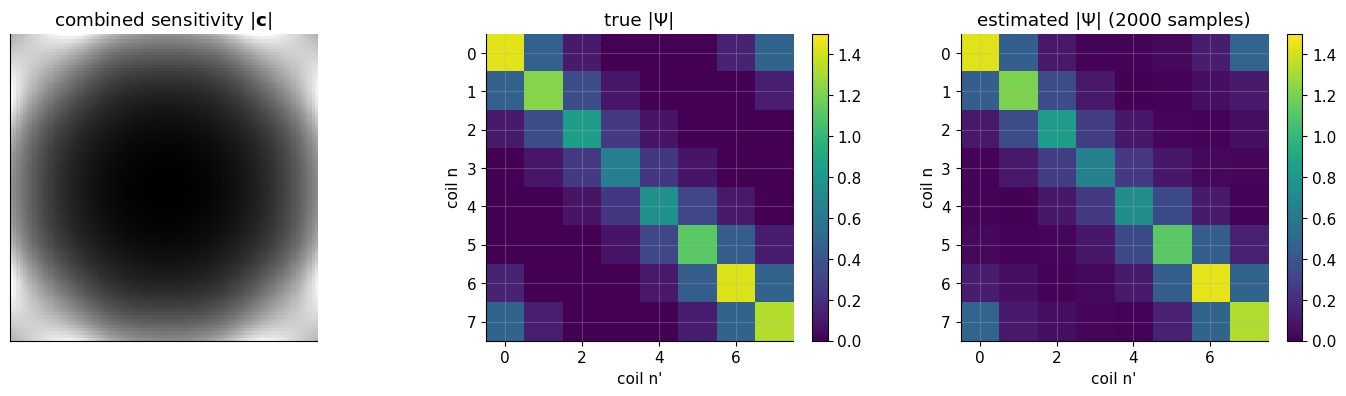

max |Psi_hat - Psi| = 0.062


In [4]:
# 8 loop coils on a ring around the head, axial plane z = 0
N = 96
FOV = 0.24
x = (np.arange(N) - N // 2) * FOV / N
X, Y = np.meshgrid(x, x)
Nc, R_ring, a_loop = 8, 0.15, 0.06
C = []
for n in range(Nc):
    phi = 2 * np.pi * n / Nc
    c, s = np.cos(phi), np.sin(phi)
    P = np.stack([c * X + s * Y, -s * X + c * Y, np.zeros_like(X)], -1)     # points in the coil's frame
    B = mt.loop_coil_field(P, a_loop, 1.0, center=(R_ring, 0, 0), normal="x", n_segments=64)
    Bx, By = c * B[..., 0] - s * B[..., 1], s * B[..., 0] + c * B[..., 1]     # rotate the field back
    C.append(Bx + 1j * By)        # receive sensitivity ~ transverse field (conjugation convention irrelevant here)
C = np.array(C); C /= np.abs(C).max()

ph = mt.tissue_phantom(N)
obj = mt.spin_echo_signal(15e-3, 0.6, ph["T1"], ph["T2"], ph["M0"]) * (ph["labels"] > 0)
mask = ph["labels"] > 0

# noise covariance: neighbours correlated (circular), slightly different channel noise levels
dist = np.minimum(np.abs(np.subtract.outer(range(Nc), range(Nc))), Nc - np.abs(np.subtract.outer(range(Nc), range(Nc))))
rho = np.where(dist == 0, 1.0, np.where(dist == 1, 0.35, np.where(dist == 2, 0.1, 0.0)))
sig = 1 + 0.2 * np.cos(np.arange(Nc))                     # per-channel noise std (preamp differences)
Psi = rho * np.outer(sig, sig) * (1 + 0j)
print("Psi positive definite:", np.all(np.linalg.eigvalsh(Psi) > 0))
L = np.linalg.cholesky(Psi)                               # Psi = L L^H

rng = np.random.default_rng(0)
def coil_noise(shape, rng):
    """Correlated complex noise with covariance Psi: eta = L w, w white with E|w|^2 = 1."""
    w = (rng.standard_normal((Nc,) + shape) + 1j * rng.standard_normal((Nc,) + shape)) / np.sqrt(2)
    return np.tensordot(L, w, axes=1)

noise_scan = coil_noise((2000,), rng)                     # 2000 noise-only samples per channel
Psi_hat = noise_scan @ noise_scan.conj().T / noise_scan.shape[1]
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
mt.show_image(np.sqrt((np.abs(C)**2).sum(0)), ax=ax[0], title="combined sensitivity $|\\mathbf{c}|$")
for a_, M_, t in [(ax[1], np.abs(Psi), "true |Ψ|"), (ax[2], np.abs(Psi_hat), "estimated |Ψ| (2000 samples)")]:
    im_ = a_.imshow(M_, cmap="viridis", vmin=0, vmax=1.5); a_.set_title(t); a_.set_xlabel("coil n'"); a_.set_ylabel("coil n")
    plt.colorbar(im_, ax=a_, fraction=0.046)
plt.tight_layout(); plt.show()
print(f"max |Psi_hat - Psi| = {np.abs(Psi_hat - Psi).max():.3f}")

The estimate from 2000 samples per channel reproduces the banded structure (neighbouring coils correlated by 0.35). The statistical error of each entry scales as $1/\sqrt{N_s}$.

## 5. Optimal coil combination (Roemer) vs sum-of-squares

### 5.1 Derivation of the SNR-optimal weights

We combine the coils linearly, $\hat m=\mathbf w^H\mathbf s$. Then

$$\hat m=\underbrace{(\mathbf w^H\mathbf c)\,m}_{\text{signal}}+\underbrace{\mathbf w^H\boldsymbol\eta}_{\text{noise}},\qquad \mathrm{Var}(\mathbf w^H\boldsymbol\eta)=E[\mathbf w^H\boldsymbol\eta\boldsymbol\eta^H\mathbf w]=\mathbf w^H\boldsymbol\Psi\mathbf w$$

so

$$SNR(\mathbf w)=\frac{|\mathbf w^H\mathbf c|\,|m|}{\sqrt{\mathbf w^H\boldsymbol\Psi\mathbf w}}$$

In words: the combined signal is a weighted sum of the coil signals; its noise variance is a quadratic form in the weights involving the noise covariance.

<details><summary><b>📐 Derivation (optional): maximising SNR via pre-whitening and Cauchy–Schwarz</b></summary>

Write $\boldsymbol\Psi=\mathbf L\mathbf L^H$ (Cholesky) and define the whitened weights $\mathbf u=\mathbf L^H\mathbf w$ and whitened sensitivities $\tilde{\mathbf c}=\mathbf L^{-1}\mathbf c$. Then $\mathbf w^H\boldsymbol\Psi\mathbf w=\mathbf u^H\mathbf u$ and $\mathbf w^H\mathbf c=\mathbf u^H\tilde{\mathbf c}$, so

$$SNR=|m|\frac{|\mathbf u^H\tilde{\mathbf c}|}{\|\mathbf u\|}\le|m|\,\|\tilde{\mathbf c}\|$$

by the Cauchy–Schwarz inequality, with equality iff $\mathbf u\propto\tilde{\mathbf c}$, i.e. $\mathbf w\propto\mathbf L^{-H}\mathbf L^{-1}\mathbf c=\boldsymbol\Psi^{-1}\mathbf c$. Since $\|\tilde{\mathbf c}\|^2=\mathbf c^H\mathbf L^{-H}\mathbf L^{-1}\mathbf c=\mathbf c^H\boldsymbol\Psi^{-1}\mathbf c$, the maximum is as below. Choosing the scale so that $\mathbf w^H\mathbf c=1$ gives an unbiased image $\hat m=m+$noise.

</details>

$$\mathbf w_{opt}=\frac{\boldsymbol\Psi^{-1}\mathbf c}{\mathbf c^H\boldsymbol\Psi^{-1}\mathbf c},\qquad SNR_{opt}=|m|\sqrt{\mathbf c^H\boldsymbol\Psi^{-1}\mathbf c}$$

In words: weight each coil by its sensitivity, "de-correlated" by the inverse noise covariance; the best achievable SNR is the length of the whitened sensitivity vector. This is the **Roemer** (1990) optimal combination ("adaptive combine" when $\mathbf c$ is estimated from the data).
Where: $\mathbf w_{opt}$ = optimal weights; $\boldsymbol\Psi^{-1}$ = inverse noise covariance. For uncorrelated, equal noise ($\boldsymbol\Psi=\sigma^2\mathbf I$): $\mathbf w\propto\mathbf c$ — each coil weighted by how well it sees the pixel (a **matched filter**), and $SNR_{opt}=|m|\,\|\mathbf c\|/\sigma$.

### 5.2 Sum-of-squares

The **sum-of-squares** (SoS) combination needs no sensitivity maps:

$$\hat m_{SoS}=\sqrt{\mathbf s^H\mathbf s}=\sqrt{\sum_n|s_n|^2}$$

In words: the root of the summed squared coil magnitudes.
At high SNR, $\mathbf s\approx\mathbf c\,m$, so $\hat m_{SoS}\approx\|\mathbf c\|\,|m|$ — equivalent to using weights $\mathbf w=\mathbf c/\|\mathbf c\|$, the optimum for $\boldsymbol\Psi\propto\mathbf I$. With correlated or unequal noise, SoS is suboptimal; **pre-whitening** first ($\tilde{\mathbf s}=\mathbf L^{-1}\mathbf s$, then SoS: $\sqrt{\mathbf s^H\boldsymbol\Psi^{-1}\mathbf s}$) restores optimality at high SNR (Larsson et al. 2003). Drawbacks of SoS: it is a magnitude image (phase lost), its intensity is weighted by $\|\mathbf c\|$ (shading), and at low SNR it has a positive **noise bias** (noise magnitudes add up: the background is not zero but $\approx\sigma\sqrt{2N_c}$-ish, a non-central chi distribution).

### 5.3 Simulation: SNR maps by Monte Carlo ("pseudo-replica")

We simulate 100 noisy repetitions of the coil images, combine each with five methods, and compute SNR = mean / standard deviation over repetitions at each pixel. The Roemer combination uses the true sensitivities; "adaptive" uses sensitivities estimated from the (noisy) data itself (low-resolution coil images / low-resolution SoS).

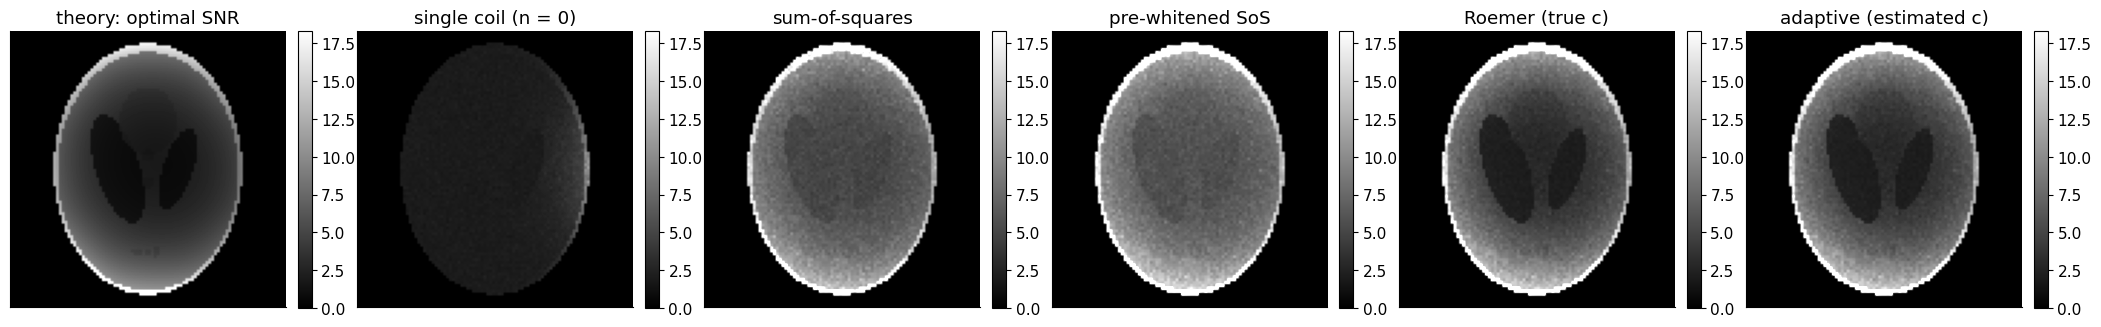

method                    median SNR / optimal SNR (inside object)
single coil (n = 0)       0.542
sum-of-squares            1.718
pre-whitened SoS          1.906
Roemer (true c)           1.498
adaptive (estimated c)    1.504


In [5]:
n_rep = 100
noise_level = 0.02
coil_imgs = C * obj[None]                                  # noiseless coil images (Nc, N, N)
Psi_inv = np.linalg.inv(Psi)
Linv = np.linalg.inv(L)

# Roemer weights with the true sensitivities, normalised to unit gain
num = np.einsum("ab,bxy->axy", Psi_inv, C)                 # Psi^-1 c
den = np.einsum("axy,axy->xy", C.conj(), num).real         # c^H Psi^-1 c
w_opt = num / den
SNR_theory = np.abs(obj) * np.sqrt(den) / noise_level      # |m| sqrt(c^H Psi^-1 c) / scale

def estimate_sens(imgs, ksize=12):
    """Sensitivity estimate: low-pass coil images divided by low-pass SoS (a common practical approach)."""
    K = mt.fft2c(imgs)
    win = np.zeros((N, N)); c0 = N // 2
    win[c0 - ksize:c0 + ksize, c0 - ksize:c0 + ksize] = np.outer(np.hanning(2 * ksize), np.hanning(2 * ksize))
    low = mt.ifft2c(K * win)
    return low / (np.sqrt((np.abs(low)**2).sum(0)) + 1e-9)

methods = {"single coil (n = 0)": [], "sum-of-squares": [], "pre-whitened SoS": [],
           "Roemer (true c)": [], "adaptive (estimated c)": []}
for rep in range(n_rep):
    s = coil_imgs + noise_level * coil_noise((N, N), rng)
    s_white = np.einsum("ab,bxy->axy", Linv, s)
    c_est = estimate_sens(s)
    num_e = np.einsum("ab,bxy->axy", Psi_inv, c_est)
    w_e = num_e / np.einsum("axy,axy->xy", c_est.conj(), num_e).real
    methods["single coil (n = 0)"].append(np.abs(s[0]))
    methods["sum-of-squares"].append(np.sqrt((np.abs(s)**2).sum(0)))
    methods["pre-whitened SoS"].append(np.sqrt((np.abs(s_white)**2).sum(0)))
    methods["Roemer (true c)"].append(np.abs(np.einsum("axy,axy->xy", w_opt.conj(), s)))
    methods["adaptive (estimated c)"].append(np.abs(np.einsum("axy,axy->xy", w_e.conj(), s)))

snr_maps = {k: np.mean(v, 0) / (np.std(v, 0) + 1e-12) * mask for k, v in methods.items()}
fig, ax = plt.subplots(1, 6, figsize=(21, 3.8))
vmax_snr = np.percentile(SNR_theory[mask], 99)
mt.show_image(SNR_theory * mask, ax=ax[0], vmax=vmax_snr, title="theory: optimal SNR", colorbar=True)
for a_, (k, v) in zip(ax[1:], snr_maps.items()):
    mt.show_image(v, ax=a_, vmax=vmax_snr, title=k, colorbar=True)
plt.tight_layout(); plt.show()
print(f"{'method':25s} median SNR / optimal SNR (inside object)")
for k, v in snr_maps.items():
    print(f"{k:25s} {np.median(v[mask] / SNR_theory[mask]):.3f}")

The Monte Carlo SNR of the Roemer combination matches the theoretical optimum (ratio ≈ 1, within Monte Carlo error of ~7 % for 100 replicas). Plain SoS loses a few percent to ~10 % because it ignores the noise correlation and the unequal channel noise; pre-whitening recovers essentially all of it. The adaptive combination with *estimated* sensitivities is close to optimal too. A single coil has high SNR only near itself — the reason for arrays. The centre of the head has the lowest SNR (all coils far away): a basic property of surface-coil arrays.

> **🔧 Engineering reality:** Vendors measure $\boldsymbol\Psi$ in a few-second noise prescan and pre-whiten all data ("noise decorrelation"). Arrays are designed so that neighbouring elements overlap to cancel mutual inductance, and low-input-impedance **preamplifier decoupling** suppresses currents in each element so that coupling (and noise correlation) stays low ([RF System and Receive Chain](B5_RF_System_and_Receive_Chain.ipynb)). Typical measured correlations: 0.05–0.4 between neighbours.

### 5.4 Noise bias of magnitude/SoS images at low SNR

In the background ($m=0$) a magnitude image is not zero: for one channel, $|\eta|$ follows a **Rayleigh** distribution with mean $\sigma\sqrt{\pi/2}\approx1.25\sigma$ (per real/imag std $\sigma$); SoS of $N_c$ channels follows a (non-central) chi distribution with $2N_c$ degrees of freedom whose mean grows like $\sigma\sqrt{2N_c}$. This biases SNR measurements made from background regions and low-SNR quantitative maps (e.g. diffusion at high b-values). The robust way to measure SNR is the **difference method** (two identical scans, $\sigma=\mathrm{std}(I_1-I_2)/\sqrt2$) or the pseudo-replica method above.

In [6]:
rng2 = np.random.default_rng(5)
sigma = 1.0
for Nc_ in [1, 8, 32]:
    eta = sigma * (rng2.standard_normal((Nc_, 200000)) + 1j * rng2.standard_normal((Nc_, 200000)))
    sos = np.sqrt((np.abs(eta)**2).sum(0))
    print(f"Nc = {Nc_:2d}: background mean of SoS = {sos.mean():.2f} sigma, std = {sos.std():.2f} sigma "
          f"(sqrt(2 Nc) = {np.sqrt(2*Nc_):.2f})")
print(f"Rayleigh mean for one channel, theory sigma*sqrt(pi/2) = {np.sqrt(np.pi/2):.3f}")

Nc =  1: background mean of SoS = 1.25 sigma, std = 0.65 sigma (sqrt(2 Nc) = 1.41)
Nc =  8: background mean of SoS = 3.94 sigma, std = 0.70 sigma (sqrt(2 Nc) = 4.00)


Nc = 32: background mean of SoS = 7.97 sigma, std = 0.71 sigma (sqrt(2 Nc) = 8.00)
Rayleigh mean for one channel, theory sigma*sqrt(pi/2) = 1.253


## 6. Parallel imaging SNR and the g-factor

With $R$-fold undersampling, each pixel of the aliased coil images contains $R$ object points (see [Accelerated Imaging Methods](H3_Accelerated_Imaging_Methods.ipynb), [Artifacts](I2_Artifacts.ipynb) Section 8):

$$\mathbf a=\mathbf S\,\mathbf m+\boldsymbol\eta_a$$

where $\mathbf a\in\mathbb C^{N_c}$ = aliased coil values, $\mathbf S$ = $N_c\times R$ matrix whose columns are the sensitivity vectors $\mathbf c$ at the $R$ aliased positions, $\mathbf m\in\mathbb C^R$ the unknown pixel values. The SENSE solution with noise weighting is the generalised least-squares estimate

$$\hat{\mathbf m}=(\mathbf S^H\boldsymbol\Psi^{-1}\mathbf S)^{-1}\mathbf S^H\boldsymbol\Psi^{-1}\mathbf a,\qquad \mathrm{Cov}(\hat{\mathbf m})\propto(\mathbf S^H\boldsymbol\Psi^{-1}\mathbf S)^{-1}$$

In words: the unfolding is a pixel-wise inversion; its noise is set by how well-conditioned the sensitivity matrix is.

<details><summary><b>📐 Derivation (optional): the g-factor</b></summary>

With orthonormal FFTs, the reduced-FOV image is built from $1/R$ of the samples, so its noise covariance is $R\boldsymbol\Psi$ (relative to the full image) when the aliased signal is written as a plain sum as above. The unfolded noise variance at point $\rho$ is then $R\,[(\mathbf S^H\boldsymbol\Psi^{-1}\mathbf S)^{-1}]_{\rho\rho}$. The fully sampled optimal (Roemer) combination at the same point has noise variance $1/(\mathbf c_\rho^H\boldsymbol\Psi^{-1}\mathbf c_\rho)=1/[\mathbf S^H\boldsymbol\Psi^{-1}\mathbf S]_{\rho\rho}$. The SNR ratio is therefore

$$\frac{SNR_{full}}{SNR_{acc}}=\sqrt R\,\sqrt{[(\mathbf S^H\boldsymbol\Psi^{-1}\mathbf S)^{-1}]_{\rho\rho}\,[\mathbf S^H\boldsymbol\Psi^{-1}\mathbf S]_{\rho\rho}}\equiv\sqrt R\,g_\rho.$$

$g_\rho\ge1$ (equality when the sensitivity vectors of the aliased points are orthogonal in the $\boldsymbol\Psi^{-1}$ inner product).

</details>

$$SNR_{acc}=\frac{SNR_{full}}{g\sqrt R},\qquad g_\rho=\sqrt{[(\mathbf S^H\boldsymbol\Psi^{-1}\mathbf S)^{-1}]_{\rho\rho}\,[\mathbf S^H\boldsymbol\Psi^{-1}\mathbf S]_{\rho\rho}}\ \ge1$$

In words: $\sqrt R$ is the unavoidable loss from measuring $R$ times less data; $g$ is the additional, spatially varying loss from the unfolding.
Where: $\rho$ = index of the pixel among the $R$ aliased ones.

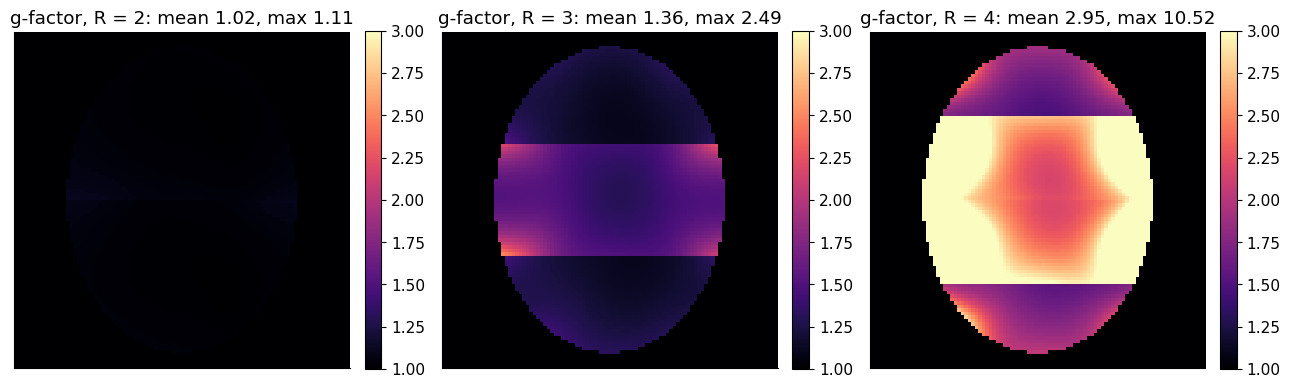

In [7]:
def g_factor_map(C, Psi, R):
    """SENSE g-factor along rows (PE = vertical) for sensitivities C (Nc, N, N)."""
    Nc_, N_, _ = C.shape
    Pinv = np.linalg.inv(Psi)
    g = np.zeros((N_, N_))
    n_red = N_ // R
    for i in range(n_red):
        ys = (i + np.arange(R) * n_red) % N_
        Smat = np.moveaxis(C[:, ys, :], 2, 0)                  # (N, Nc, R): one matrix per column x
        A = np.conj(np.swapaxes(Smat, 1, 2)) @ Pinv @ Smat     # S^H Psi^-1 S  (N, R, R)
        Ainv = np.linalg.inv(A + 1e-9 * np.eye(R))
        g[ys, :] = np.sqrt(np.abs(np.diagonal(Ainv, axis1=1, axis2=2) * np.diagonal(A, axis1=1, axis2=2))).T
    return g

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a_, R in zip(ax, [2, 3, 4]):
    g = g_factor_map(C, Psi, R) * mask
    mt.show_image(g, ax=a_, vmin=1, vmax=3, cmap="magma", colorbar=True,
                  title=f"g-factor, R = {R}: mean {g[mask].mean():.2f}, max {g[mask].max():.2f}")
plt.tight_layout(); plt.show()

For $R=2$ the g-factor is close to 1 almost everywhere (8 coils on a ring easily separate points half a FOV apart); at $R=4$ it rises, especially in the centre where the aliased points are seen by the same coils. Total SNR loss at a pixel is $g\sqrt R$.

> **TODO (polish):** verify the g-factor map with a pseudo-replica SENSE reconstruction (Monte Carlo) as in Section 5.3; discuss GRAPPA g-factors and CAIPIRINHA.

> **🔧 Engineering reality:** SNR also depends on hardware choices discussed elsewhere: intrinsic SNR grows roughly linearly with $B_0$ (between $B_0^1$ and $B_0^{1.65}$ in practice) because the signal grows as $B_0^2$ while body noise grows ~$B_0$; preamplifier noise figures of 0.5 dB cost ~6 % SNR; dense arrays (32–64 channels) gain most near the surface and less in the centre. The ultimate intrinsic SNR (best possible coil) is an active research topic.

> **TODO (polish):** add a worked numerical example of B0 scaling and noise-figure impact; fact-check the B0 exponent range against a reference.

## Key takeaways

* $SNR\propto\sqrt{T_{meas}}$ assumes constant signal; with $T_2^*$ decay the optimal readout is $T_{read}\approx1.26\,T_2^*$ (gradient echo) or $2.5\,T_2^*$ (spin echo), but resolution/off-resonance usually favour shorter readouts.
* At the Ernst angle, spoiled-GRE SNR efficiency tends to $M_0/\sqrt{2T_1}$ for $TR\ll T_1$ — nearly TR-independent.
* Coil noise is correlated; $\boldsymbol\Psi=E[\boldsymbol\eta\boldsymbol\eta^H]$ is measured with a noise scan.
* Optimal (Roemer) combination: $\mathbf w\propto\boldsymbol\Psi^{-1}\mathbf c$, $SNR_{opt}=|m|\sqrt{\mathbf c^H\boldsymbol\Psi^{-1}\mathbf c}$; SoS is near-optimal after pre-whitening at high SNR but biased at low SNR.
* Parallel imaging: $SNR_{acc}=SNR/(g\sqrt R)$ with $g_\rho=\sqrt{[(\mathbf S^H\boldsymbol\Psi^{-1}\mathbf S)^{-1}]_{\rho\rho}[\mathbf S^H\boldsymbol\Psi^{-1}\mathbf S]_{\rho\rho}}\ge1$.

## Check your understanding

1. A tissue has $T_2^*$ = 5 ms (e.g. iron-loaded liver). What readout duration maximizes SNR in a gradient echo, and why might you choose shorter?

<details><summary>Answer</summary>

$T_{read}\approx1.26\times5$ ms ≈ 6.3 ms. Shorter readouts reduce $T_2^*$ blurring (blur ≈ $T_{read}/(\pi T_2^*)$ pixels from I1) and off-resonance shifts, at a small SNR cost because the optimum is broad.

</details>

2. Why does SoS lose SNR when two coils have strongly correlated noise?

<details><summary>Answer</summary>

SoS effectively uses $\mathbf w\propto\mathbf c$, which is optimal only for $\boldsymbol\Psi\propto\mathbf I$. With correlation, the noise of the two coils adds partly coherently in the sum and is not "averaged out" as assumed; the optimal weights $\boldsymbol\Psi^{-1}\mathbf c$ partially subtract the common noise. Pre-whitening fixes this.

</details>

3. Show that for uncorrelated equal noise the optimal SNR is $|m|\,\|\mathbf c\|/\sigma$.

<details><summary>Answer</summary>

With $\boldsymbol\Psi=\sigma^2\mathbf I$, $\mathbf c^H\boldsymbol\Psi^{-1}\mathbf c=\|\mathbf c\|^2/\sigma^2$, so $SNR_{opt}=|m|\sqrt{\|\mathbf c\|^2/\sigma^2}=|m|\|\mathbf c\|/\sigma$.

</details>

4. A protocol uses $R=3$ and the g-factor in the region of interest is 1.4. By how much did the SNR drop compared with the fully sampled scan?

<details><summary>Answer</summary>

$g\sqrt R=1.4\times1.73\approx2.4$, i.e. SNR drops to ~41 %.

</details>

5. Why is the SNR efficiency of spoiled GRE at the Ernst angle nearly constant for short TR?

<details><summary>Answer</summary>

At the Ernst angle $f_{seq}=M_0\sqrt{(1-E_1)/(1+E_1)}\approx M_0\sqrt{TR/(2T_1)}$ for $TR\ll T_1$; dividing by $\sqrt{TR}$ cancels the TR dependence, giving $M_0/\sqrt{2T_1}$.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Advanced SNR". Changes: added noise recap, closed-form optimum readout derivation, Ernst-angle efficiency limit derivation, noise covariance, Roemer vs sum-of-squares derivation and Monte Carlo simulation, noise bias, SENSE g-factor derivation and maps; corrected the two-sided decay integrand ($|e^{-\tau/T_2^*}|\to e^{-|\tau|/T_2^*}$), wrote out $f_{seq,GRE}$, fixed "applieds".*